# 04 · EMT-TF Expression (unconditional final step)

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

### Setup & paths

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Derive informative EMT-TF pair

In [3]:
# EMT-TF panel — expressed factors only, incl. FOXC/PRRX families (VIM excluded: mesenchymal marker, not a TF)
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn=(t-t.min())/(t.max()-t.min())
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn,1/3); late = tn >= np.quantile(tn,2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows=[]
for j,g in enumerate(present):
    x=X[:,j]; rho,p=spearmanr(tn,x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t']).sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t
 FOXC1      0.236       0.193      0.096    -0.202
 PRRX2      0.040       0.030      0.008    -0.128
  ZEB1      0.083       0.059      0.055    -0.070
 SNAI2      0.077       0.035      0.029    -0.057
 SNAI1      0.013       0.008      0.006    -0.037
 PRRX1      0.005       0.002      0.003    -0.016
TWIST1      0.004       0.001      0.003    -0.009
  ZEB2      0.064       0.029      0.089     0.069

derived pair: FOXC1 (early/root) <-> ZEB2 (late/terminus)


### Figure — expression.pdf

overlay thresholds (upper quartile among expressers): {'FOXC1': 0.817, 'ZEB2': 0.973} | cells shown: {'FOXC1': 463, 'ZEB2': 126}
FOXC1: 23.6% expressing; 463 shown, mean pseudotime of shown = 0.42 (all = 0.48)
ZEB2: 6.4% expressing; 126 shown, mean pseudotime of shown = 0.84 (all = 0.48)
saved expression.pdf


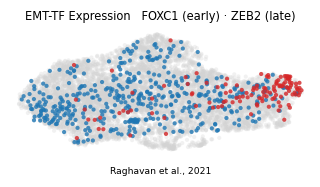

In [4]:
# expression.pdf — categorical thresholded-expresser overlay on grey (NOT a continuous colormap)
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def vec(g):
    x=adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr={}
for g in [early_tf, late_tf]:
    v=vec(g); pos=v[v>0]; thr[g]=float(np.quantile(pos,0.75)) if pos.size else 0.0
sel={g: vec(g)>thr[g] for g in [early_tf,late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g:round(thr[g],3) for g in sel},
      '| cells shown:', {g:int(sel[g].sum()) for g in sel})
order = sorted([early_tf,late_tf], key=lambda g:-int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) \u00b7 {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Raghavan et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf,late_tf]:
    m=sel[g]; print(f'{g}: {(vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown, '
                     f'mean pseudotime of shown = {tn[m].mean():.2f} (all = {tn.mean():.2f})')
print('saved expression.pdf')